# 입출력과 출처 검증

**이 노트북에서 할 일**

1. 이번 검색 결과 문서 하나로 허용 목록을 만듭니다.
2. 같은 문서를 붙여 모델에게 한 번 묻고 답을 받습니다.
3. 검사 없이 받는 흐름이 질문도 답도 하나도 막지 못하는 것을 봅니다(Before).
4. 입력 검사와 출력 검사를 붙여 막아야 할 질문 둘과 답 둘을 막습니다(After).

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델 `gpt-5.4-mini`에 보내는 요청은 한 번이고 임베딩 요청은 없습니다.
노트북을 한 번 실행하는 요금은 요금표로 어림해 미화 0.01달러 아래입니다.
실제 청구 금액과는 다를 수 있습니다.

읽는 파일은 이 챕터 자료 파일 `data/retrieved-documents.json` 하나입니다.
새로 쓰는 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 4초 만에 끝났습니다.

합성 답 두 개는 자료 파일에 없고 이 절에서 손으로 적은 답입니다.
검사가 무엇을 막는지 보이려고 정한 답입니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~6절을 읽습니다.
검색 결과로 허용 목록을 만들고, 검사 없는 흐름이 무엇을 놓치는지 보는 자리입니다.
7~9절은 입력 검사와 출력 검사를 붙이는 자리입니다.
10절은 값 바꿔 보기이고 9절과 함께 실습 시간에 실행합니다.

실습 폴더 `labs/part4/ch16-guardrails`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 초록 상자 받은 질문 빈칸과 길이가 제각각에서 파란 상자 입력 검사 빈칸 정리 빈 질문 글자 수 상한 500으로, 다시 보라 상자 모델 gpt-5.4-mini 답을 한 문장으로 씀으로, 다시 노란 상자 답에서 뽑은 출처 표시로, 다시 파란 상자 출력 검사 표시를 허용 목록과 대조로 이어지고 그 옆 노란 상자 허용 목록 이번 검색 결과로 만듦도 같은 출력 검사로 들어가며 맨 아래 노란 상자 내보낸 답 검사를 통과한 답만으로 끝나는 그림](attachment:01-1-질문-검사와-출처-대조.png)

위에서 아래로 읽습니다. 초록 질문이 파란 입력 검사를 지나 보라 모델로 들어갑니다.
모델 답에서 뽑은 노란 출처 표시가 노란 허용 목록과 함께 파란 출력 검사로 들어갑니다.
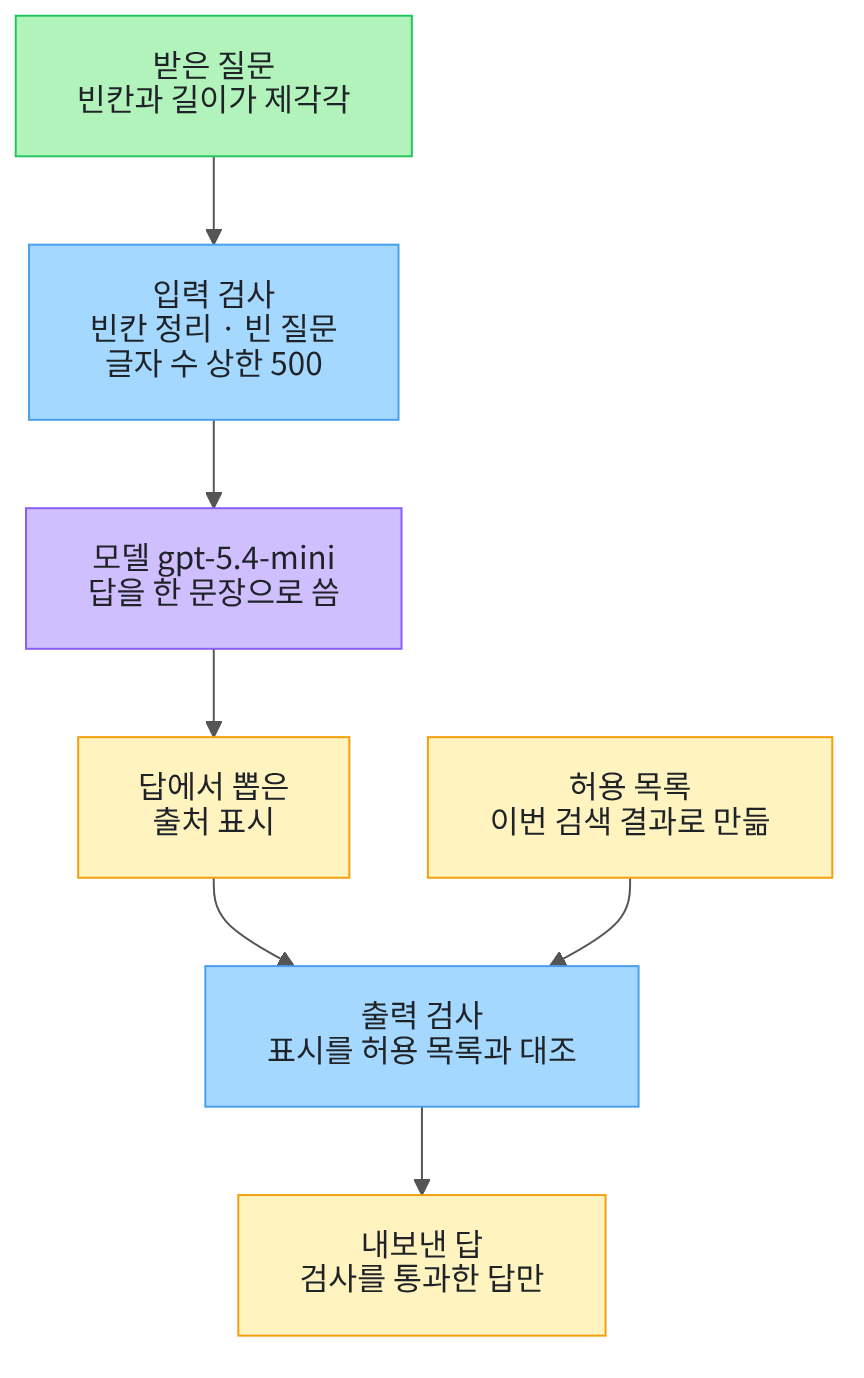

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름 셋을 불러옵니다.

In [2]:
# 자료 파일을 읽을 이름과 모델을 만들 이름을 불러옵니다
import json
import os

from langchain.chat_models import init_chat_model

print("불러온 이름:", "json", "os", "init_chat_model")

불러온 이름: json os init_chat_model


**결과 읽기** — 출력 줄 `불러온 이름: json os init_chat_model`로 이름 셋을 불러왔습니다.

## 2. 키와 모델 준비

이 절은 답을 쓰는 모델 `gpt-5.4-mini`를 한 번 부릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 답 문장이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-23에 이 모델로 실행한 결과입니다.

## 3. 이번 검색 결과와 허용 목록의 재료

먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
Ch 14·Ch 15와 같은 자리 찾기 셀입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch16-guardrails/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.

다음 셀은 이 챕터 자료 파일을 읽습니다.
문서마다 문서 ID와 쪽 번호, 제목이 들어 있습니다.

In [6]:
# 이 챕터 자료 파일을 읽어 문서 목록을 만듭니다(읽기만 합니다)
data_path = root_path + "/labs/part4/ch16-guardrails/data"
with open(data_path + "/retrieved-documents.json", encoding="utf-8") as file:
    all_documents = json.loads(file.read())
print("자료 파일의 문서 수:", len(all_documents))
print("문서 ID | 쪽 | 제목")
for document in all_documents:
    print(document["doc_id"], "|", document["page"], "|", document["title"])

자료 파일의 문서 수: 2
문서 ID | 쪽 | 제목
E01 | 1 | 미르시립도서관 이용 안내
E99 | 1 | 로컬 공격 학습 문서


**결과 읽기** — 출력 줄 `자료 파일의 문서 수: 2`로 문서는 둘입니다.
라벨 줄 `문서 ID | 쪽 | 제목` 아래 두 줄이 문서 하나씩입니다.
줄 `E01 | 1 | 미르시립도서관 이용 안내`가 도서관 안내문입니다.
줄 `E99 | 1 | 로컬 공격 학습 문서`는 06절에서 쓸 합성 문서라 이 절에서는 고르지 않습니다.

다음 셀은 이 절의 검색 결과로 쓸 문서만 고릅니다.

In [7]:
# 이 절의 검색 결과로 쓸 문서만 고릅니다: 안내 문서 E01 하나입니다
retrieved = []
for document in all_documents:
    if document["doc_id"] == "E01":
        retrieved.append(document)
print("이번 검색 결과의 문서 수:", len(retrieved))
print("문서 본문:")
print(retrieved[0]["text"])

이번 검색 결과의 문서 수: 1
문서 본문:
미르시립도서관은 매주 월요일과 법정 공휴일에 휴관합니다. 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다.


**결과 읽기** — 출력 줄 `이번 검색 결과의 문서 수: 1`로 이 절의 검색 결과는 문서 하나입니다.
라벨 줄 `문서 본문:` 아래 한 줄이 그 문서의 본문입니다.
휴관일이 적혀 있어 이 절의 질문에 답할 수 있습니다.

## 4. 이 절에서 정한 값

다음 셀은 이 절에서 정한 값 둘을 적습니다.
질문 글자 수 상한과 모델에게 보낼 시스템 메시지 글입니다.

In [8]:
# 이 절에서 정한 값입니다: 질문 글자 수 상한과 모델에게 보낼 시스템 메시지 글입니다
max_chars = 500
system_text = "검색 문서에 있는 사실만 써서 한국어 한 문장으로 답하세요. 답 끝에 쓴 문서의 출처를 [문서ID p.쪽] 꼴로 적으세요."
print("정한 질문 글자 수 상한:", max_chars)
print("시스템 메시지:")
print(system_text)

정한 질문 글자 수 상한: 500
시스템 메시지:
검색 문서에 있는 사실만 써서 한국어 한 문장으로 답하세요. 답 끝에 쓴 문서의 출처를 [문서ID p.쪽] 꼴로 적으세요.


**결과 읽기** — 출력 줄 `정한 질문 글자 수 상한: 500`이 이 절에서 정한 값입니다.
라벨 줄 `시스템 메시지:` 아래 한 줄이 모델에게 보낼 시스템 메시지 글입니다.
답 끝에 `[문서ID p.쪽]` 꼴로 출처를 적으라고 적었습니다.

다음 셀은 이 절에서 쓸 질문 넷을 적습니다.
하나는 모델에게 보낼 질문이고 셋은 입력 검사에 걸어 볼 질문입니다.
아주 긴 질문은 글 `"도서관 휴관일"`에 `repeat_count`를 곱해 만듭니다.
글에 정수를 곱하면 그 글을 그 수만큼 이어 붙입니다.

In [9]:
# 이 절에서 정한 질문입니다: 모델에게 보낼 질문 하나와 검사에 쓸 질문 셋입니다
question = "도서관 휴관일은 언제인가요?"
spaced_question = "   도서관 휴관일은   언제인가요?   "
empty_question = "   "
repeat_count = 100
long_question = "도서관 휴관일" * repeat_count
raw_questions = [spaced_question, empty_question, long_question]
print("모델에게 보낼 질문:", question)
print("검사에 쓸 질문 수:", len(raw_questions))
print("질문별 글자 수:", len(spaced_question), len(empty_question), len(long_question))

모델에게 보낼 질문: 도서관 휴관일은 언제인가요?
검사에 쓸 질문 수: 3
질문별 글자 수: 23 3 700


**결과 읽기** — 출력 줄 `모델에게 보낼 질문: 도서관 휴관일은 언제인가요?`가 이 절의 질문입니다.
출력 줄 `검사에 쓸 질문 수: 3`으로 검사에 걸어 볼 질문은 셋입니다.
출력 줄 `질문별 글자 수: 23 3 700`이 차례로 빈칸이 붙은 질문, 빈 질문, 아주 긴 질문입니다.
빈칸까지 일곱 글자인 글을 백 번 이어 붙여 700자가 되었습니다.

## 5. 모델에게 한 번 묻기

다음 셀은 시스템 메시지와 검색 문서를 붙여 모델에게 한 번 묻습니다.
이 셀에서 모델 요청이 한 번 나갑니다.

메시지는 Ch 5 04절에서 본 역할 딕셔너리 꼴 `{"role": …, "content": …}`로 적습니다.
모델 객체의 `invoke`는 Ch 6 01절의 튜플 목록처럼 이 꼴도 받습니다.
이 절은 요청을 여기서 한 번만 보내고, 검사 둘은 7~9절에서 따로 겁니다.

In [10]:
# 시스템 메시지와 검색 문서를 붙여 모델에게 한 번 묻습니다(모델 요청 1번)
document = retrieved[0]
document_line = "검색 문서 " + document["doc_id"] + " " + str(document["page"]) + "쪽: " + document["text"]
messages = [
    {"role": "system", "content": system_text},
    {"role": "user", "content": "질문: " + question + "\n" + document_line},
]
model_answer = model.invoke(messages).text
print("모델이 쓴 답:")
print(model_answer)

모델이 쓴 답:
미르시립도서관은 매주 월요일과 법정 공휴일에 휴관하며, 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다. [E01 p.1]


**결과 읽기** — 라벨 줄 `모델이 쓴 답:` 아래 한 줄이 모델 답입니다.
답 끝에 출처 표시 `[E01 p.1]`이 붙어 있습니다.

이 답은 모델이 쓴 글이라 여러분 실행에서는 문장이 다를 수 있습니다.
교재 출력을 만들기 전에 같은 요청을 따로 다섯 번 보냈고 다섯 번 모두 같은 표시가 붙었습니다.

다음 셀은 이 절에서 손으로 적은 합성 답 둘을 더해 검사 대상 목록을 만듭니다.

In [11]:
# 이 절에서 정한 합성 답 둘을 모델 답과 함께 검사 대상 목록에 담습니다
fake_answer = "도서관 휴관일은 화요일입니다. [E02 p.1]"
bare_answer = "도서관 휴관일은 월요일입니다."
raw_answers = [model_answer, fake_answer, bare_answer]
print("검사에 쓸 답 수:", len(raw_answers))
print("검색 결과에 없는 출처를 적은 합성 답:", fake_answer)
print("출처 표시가 없는 합성 답:", bare_answer)

검사에 쓸 답 수: 3
검색 결과에 없는 출처를 적은 합성 답: 도서관 휴관일은 화요일입니다. [E02 p.1]
출처 표시가 없는 합성 답: 도서관 휴관일은 월요일입니다.


**결과 읽기** — 출력 줄 `검사에 쓸 답 수: 3`으로 검사 대상 답은 셋입니다.
출력 줄 `검색 결과에 없는 출처를 적은 합성 답:` 뒤 답에는 표시 `[E02 p.1]`이 붙어 있습니다.
문서 `E02`는 이번 검색 결과에 없습니다.
출력 줄 `출처 표시가 없는 합성 답:` 뒤 답에는 대괄호 표시가 아예 없습니다.

## 6. 검사 없이 받는 흐름 (Before)

Before 셀은 받은 것을 그대로 쓰는 흐름입니다.
질문을 손보지도 막지도 않고, 답을 대조하지도 않습니다.
먼저 질문 셋을 막지 않고 보낼 목록에 담는 흐름입니다.

In [12]:
# 검사 없이 받는 흐름입니다: 질문 셋을 하나도 막지 않고 보낼 목록에 담습니다
sent_questions = []
for raw_question in raw_questions:
    sent_questions.append(raw_question)
print("받은 질문 수:", len(raw_questions))
print("보낼 목록에 담은 질문 수:", len(sent_questions))
print("막은 질문 수:", len(raw_questions) - len(sent_questions))

받은 질문 수: 3
보낼 목록에 담은 질문 수: 3
막은 질문 수: 0


**결과 읽기** — 출력 줄 `받은 질문 수: 3`과 `보낼 목록에 담은 질문 수: 3`이 같습니다.
출력 줄 `막은 질문 수: 0`이 이 흐름의 결함입니다.
이 흐름이라면 빈 질문과 아주 긴 질문도 보낼 목록에 그대로 들어갑니다.
이 절은 이 두 질문을 실제로 모델에 보내지는 않았습니다.

다음 셀은 답 셋을 그대로 내보내는 흐름입니다.

In [13]:
# 검사 없이 받는 흐름입니다: 답 셋을 대조하지 않고 그대로 내보냅니다
sent_answers = []
for raw_answer in raw_answers:
    sent_answers.append(raw_answer)
print("받은 답 수:", len(raw_answers))
print("그대로 내보낸 답 수:", len(sent_answers))
print("막은 답 수:", len(raw_answers) - len(sent_answers))

받은 답 수: 3
그대로 내보낸 답 수: 3
막은 답 수: 0


**결과 읽기** — 출력 줄 `받은 답 수: 3`과 `그대로 내보낸 답 수: 3`이 같습니다.
출력 줄 `막은 답 수: 0`이 이 흐름의 결함입니다.
답이 적은 출처를 무엇과도 대조하지 않았기 때문입니다.

다음 셀은 그대로 내보낸 답 셋을 한 줄씩 봅니다.

In [14]:
# 검사 없이 내보낸 답 셋을 한 줄씩 봅니다
print("번호 | 내보낸 답")
for i in range(len(sent_answers)):
    print(i + 1, "|", sent_answers[i])

번호 | 내보낸 답
1 | 미르시립도서관은 매주 월요일과 법정 공휴일에 휴관하며, 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다. [E01 p.1]
2 | 도서관 휴관일은 화요일입니다. [E02 p.1]
3 | 도서관 휴관일은 월요일입니다.


**결과 읽기** — 라벨 줄 `번호 | 내보낸 답` 아래 세 줄이 내보낸 답입니다.
둘째 줄 답은 표시 `[E02 p.1]`을 적었지만 그대로 나갔습니다.
셋째 줄 답은 출처 표시가 없는데도 그대로 나갔습니다.

화면만 보면 어느 표시가 이번 검색 결과에 있는 표시인지 알 수 없습니다.
그래서 다음 소절에서 검사 둘을 붙입니다.

## 7. 입력 검사 (After)

입력 검사(input validation)는 모델을 부르기 전에 질문을 보는 일입니다.
이 절의 입력 검사는 세 가지를 합니다.
먼저 앞뒤와 가운데 빈칸을 한 칸으로 정리합니다.
그다음 빈 질문과 정한 글자 수 상한을 넘는 질문을 막습니다.

막을 때는 `raise ValueError(글)` 줄로 오류를 일으킵니다.
파이썬 말 `raise`는 그 자리에서 오류를 일부러 일으켜 함수를 멈춥니다.
오류 이름 `ValueError`와 받는 쪽의 `try/except`는 Ch 2 05절에서 배웠습니다.

In [15]:
# 질문의 빈칸을 정리하고 빈 질문과 글자 수 상한을 봅니다
def validate_query(query, max_chars):
    normalized = " ".join(query.split())
    if not normalized:
        raise ValueError("질문이 비어 있습니다.")
    if len(normalized) > max_chars:
        raise ValueError("질문이 너무 깁니다. 정한 상한: " + str(max_chars))
    return normalized

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `validate_query`는 질문과 글자 수 상한을 받습니다.
먼저 `split()`으로 빈칸을 기준으로 나눕니다.
그다음 `" ".join(목록)`으로 나눈 글 사이에 빈칸 한 칸을 넣어 다시 잇습니다.

조건 `not normalized`는 정리한 글이 빈 글일 때 참이 됩니다.
정리한 글이 비었거나 상한을 넘으면 `ValueError`를 일으키고, 아니면 정리한 글을 내놓습니다.

다음 셀은 6절과 같은 질문 셋에 이 검사를 겁니다.

In [16]:
# 질문 셋에 입력 검사를 걸어 통과한 질문만 모읍니다
checked_questions = []
for raw_question in raw_questions:
    try:
        checked_questions.append(validate_query(raw_question, max_chars))
    except ValueError as error:
        print("막은 질문:", error)
print("받은 질문 수:", len(raw_questions))
print("검사를 통과한 질문 수:", len(checked_questions))

막은 질문: 질문이 비어 있습니다.
막은 질문: 질문이 너무 깁니다. 정한 상한: 500
받은 질문 수: 3
검사를 통과한 질문 수: 1


**결과 읽기** — 출력 줄 `막은 질문: 질문이 비어 있습니다.`가 빈 질문을 막은 자리입니다.
출력 줄 `막은 질문: 질문이 너무 깁니다. 정한 상한: 500`이 긴 질문을 막은 자리입니다.
출력 줄 `검사를 통과한 질문 수: 1`로 셋 가운데 하나만 지났습니다.

앞 6절 Before 셀에서는 `막은 질문 수: 0`이었습니다.

다음 셀은 통과한 질문이 어떻게 정리됐는지 봅니다.

In [17]:
# 통과한 질문에서 앞뒤 빈칸과 겹친 빈칸이 정리된 것을 봅니다
print("정리한 질문:", checked_questions[0])
print("정리 전 글자 수:", len(spaced_question))
print("정리 뒤 글자 수:", len(checked_questions[0]))

정리한 질문: 도서관 휴관일은 언제인가요?
정리 전 글자 수: 23
정리 뒤 글자 수: 15


**결과 읽기** — 출력 줄 `정리한 질문: 도서관 휴관일은 언제인가요?`에 앞뒤 빈칸이 없습니다.
출력 줄 `정리 전 글자 수: 23`과 `정리 뒤 글자 수: 15`가 정리한 양입니다.
빈칸 여덟 칸이 줄었습니다.

## 8. 답에서 출처 표시 뽑기

출처 표시는 답 끝에 `[문서ID p.쪽]` 꼴로 적는 짧은 표시입니다.
다음 셀은 답에서 대괄호로 묶은 표시를 모두 뽑는 함수입니다.
정규 표현식 대신 `split()`만 씁니다.

In [18]:
# 답에서 대괄호로 묶은 출처 표시를 모두 뽑습니다
def find_source_marks(answer):
    marks = []
    pieces = answer.split("[")
    for piece in pieces[1:]:
        if "]" in piece:
            inside = piece.split("]")[0]
            marks.append("[" + inside + "]")
    return marks

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `find_source_marks`는 답을 여는 대괄호로 나눕니다.
나눈 글 가운데 첫째는 대괄호 앞 글이라 건너뜁니다.
나머지 글마다 닫는 대괄호 앞까지를 표시로 봅니다.
표시를 찾지 못하면 빈 목록을 내놓습니다.

다음 셀은 답 셋에 이 함수를 겁니다.

In [19]:
# 답 셋에서 출처 표시를 뽑아 한 줄씩 봅니다
print("번호 | 뽑은 출처 표시")
for i in range(len(raw_answers)):
    print(i + 1, "|", find_source_marks(raw_answers[i]))

번호 | 뽑은 출처 표시
1 | ['[E01 p.1]']
2 | ['[E02 p.1]']
3 | []


**결과 읽기** — 라벨 줄 `번호 | 뽑은 출처 표시` 아래 세 줄이 답마다의 표시입니다.
첫째 줄 `1 | ['[E01 p.1]']`이 모델 답에서 뽑은 표시입니다.
둘째 줄 `2 | ['[E02 p.1]']`이 합성 답에서 뽑은 표시입니다.
셋째 줄 `3 | []`은 표시가 없는 답이라 빈 목록입니다.

## 9. 허용 목록과 대조하기

허용 목록(allow list)은 이번 검색 결과로 만든 출처 표시 목록입니다.
다음 셀은 검색 문서 목록에서 허용 목록을 만드는 함수입니다.

In [20]:
# 검색 문서 목록으로 허용 목록을 만듭니다
def allowed_marks_of(documents):
    allowed = []
    for document in documents:
        allowed.append("[" + str(document["doc_id"]) + " p." + str(document["page"]) + "]")
    return allowed

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `allowed_marks_of`는 문서마다 문서 ID와 쪽 번호를 이어 붙입니다.
답에 적힐 표시와 같은 모양으로 만들어야 글자끼리 견줄 수 있습니다.

다음 셀은 3절에서 고른 검색 결과로 허용 목록을 만듭니다.

In [21]:
# 이번 검색 결과로 이 절의 허용 목록을 만듭니다
allowed_marks = allowed_marks_of(retrieved)
print("이번 검색 결과의 문서 수:", len(retrieved))
print("허용 목록:", allowed_marks)

이번 검색 결과의 문서 수: 1
허용 목록: ['[E01 p.1]']


**결과 읽기** — 출력 줄 `허용 목록: ['[E01 p.1]']`이 이 절의 허용 목록입니다.
출력 줄 `이번 검색 결과의 문서 수: 1`과 목록 길이가 같습니다.
이 목록은 이번 검색 결과에서 만든 것이라 요청마다 달라집니다.

다음 셀은 허용 목록에 없는 표시만 모으는 함수입니다.

In [22]:
# 허용 목록에 없는 출처 표시만 모읍니다
def unknown_marks(marks, allowed_list):
    unknown = []
    for mark in marks:
        if mark not in allowed_list:
            unknown.append(mark)
    return unknown

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `unknown_marks`는 표시 목록과 허용 목록을 받습니다.
허용 목록에 없는 표시만 새 목록에 담아 내놓습니다.

다음 셀은 출력 검사(output validation) 함수입니다.
표시가 하나도 없거나 허용 목록 밖 표시가 있으면 `ValueError`를 일으킵니다.

In [23]:
# 답의 출처 표시를 허용 목록과 대조합니다
def validate_answer(answer, allowed_list):
    marks = find_source_marks(answer)
    if len(marks) == 0:
        raise ValueError("답에 [문서ID p.쪽] 출처 표시가 없습니다.")
    unknown = unknown_marks(marks, allowed_list)
    if len(unknown) > 0:
        raise ValueError("검색 결과에 없는 출처: " + ", ".join(unknown))
    return marks

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `validate_answer`는 먼저 답에서 표시를 뽑습니다.
표시가 하나도 없으면 거기서 막고, 있으면 허용 목록 밖 표시를 찾습니다.
밖 표시가 하나라도 있으면 막고, 없으면 뽑은 표시 목록을 내놓습니다.

다음 셀은 6절과 같은 답 셋에 이 검사를 겁니다.

In [24]:
# 답 셋에 출력 검사를 걸어 통과한 답만 모읍니다
passed_answers = []
for raw_answer in raw_answers:
    try:
        validate_answer(raw_answer, allowed_marks)
        passed_answers.append(raw_answer)
    except ValueError as error:
        print("막은 답:", error)
print("받은 답 수:", len(raw_answers))
print("검사를 통과한 답 수:", len(passed_answers))

막은 답: 검색 결과에 없는 출처: [E02 p.1]
막은 답: 답에 [문서ID p.쪽] 출처 표시가 없습니다.
받은 답 수: 3
검사를 통과한 답 수: 1


**결과 읽기** — 출력 줄 `막은 답: 검색 결과에 없는 출처: [E02 p.1]`이 합성 답을 막은 자리입니다.
출력 줄 `막은 답: 답에 [문서ID p.쪽] 출처 표시가 없습니다.`가 표시 없는 답을 막은 자리입니다.
출력 줄 `검사를 통과한 답 수: 1`로 셋 가운데 하나만 지났습니다.

앞 6절 Before 셀에서는 `막은 답 수: 0`이었습니다.

다음 셀은 통과한 답과 그 답이 쓴 표시를 봅니다.

In [25]:
# 검사를 통과한 답과 그 답이 쓴 출처 표시를 봅니다
print("통과한 답:", passed_answers[0])
print("대조한 허용 목록:", allowed_marks)
print("답이 쓴 출처 표시:", find_source_marks(passed_answers[0]))

통과한 답: 미르시립도서관은 매주 월요일과 법정 공휴일에 휴관하며, 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다. [E01 p.1]
대조한 허용 목록: ['[E01 p.1]']
답이 쓴 출처 표시: ['[E01 p.1]']


**결과 읽기** — 출력 줄 `대조한 허용 목록: ['[E01 p.1]']`과 `답이 쓴 출처 표시: ['[E01 p.1]']`이 같습니다.
두 목록이 같아서 이 답이 검사를 지났습니다.
출력 줄 `통과한 답:` 뒤는 모델이 쓴 답이라 실행마다 문장이 다를 수 있습니다.

다음 셀은 손으로 적은 글자로 검사 함수 셋을 확인합니다.
모델이 쓴 답이 아니라 미리 정한 글자라 `assert`로 확인할 수 있습니다.

In [26]:
# 손으로 적은 글자로 검사 함수 셋을 확인합니다(모델 답이 아니라 미리 정한 값이라 assert로 봅니다)
print("정리 결과:", validate_query("  휴관일은   언제인가요? ", max_chars))
print("표시 뽑기:", find_source_marks("답입니다. [E01 p.1]"))
print("허용 목록 밖 표시:", unknown_marks(["[E02 p.1]"], ["[E01 p.1]"]))
assert validate_query("  휴관일은   언제인가요? ", max_chars) == "휴관일은 언제인가요?"
assert find_source_marks("답입니다. [E01 p.1]") == ["[E01 p.1]"]
assert unknown_marks(["[E02 p.1]"], ["[E01 p.1]"]) == ["[E02 p.1]"]

정리 결과: 휴관일은 언제인가요?
표시 뽑기: ['[E01 p.1]']
허용 목록 밖 표시: ['[E02 p.1]']


**결과 읽기** — 출력 줄 `정리 결과: 휴관일은 언제인가요?`가 빈칸을 정리한 결과입니다.
출력 줄 `표시 뽑기: ['[E01 p.1]']`이 손으로 적은 답에서 뽑은 표시입니다.
출력 줄 `허용 목록 밖 표시: ['[E02 p.1]']`이 목록 밖 표시입니다.
마지막 세 줄의 `assert`도 통과했습니다.

## 10. 값 바꿔 보기 · 허용 목록을 넓히면

바꿀 값은 허용 목록 하나입니다. 손으로 `[E02 p.1]`을 더한 목록을 만듭니다.

실행 전에 예상해 봅니다.
넓힌 목록에서는 합성 답의 표시가 목록 안에 들어가 밖 표시가 없을 것입니다.

In [27]:
# 바꿀 값은 허용 목록 하나입니다: 손으로 [E02 p.1]을 더한 목록으로 다시 대조합니다
wider_marks = allowed_marks + ["[E02 p.1]"]
fake_marks = find_source_marks(fake_answer)
print("넓힌 허용 목록:", wider_marks)
print("합성 답의 출처 표시:", fake_marks)
print("넓힌 목록에서 남은 밖 표시:", unknown_marks(fake_marks, wider_marks))
print("이번 검색 결과 목록에서 남은 밖 표시:", unknown_marks(fake_marks, allowed_marks))

넓힌 허용 목록: ['[E01 p.1]', '[E02 p.1]']
합성 답의 출처 표시: ['[E02 p.1]']
넓힌 목록에서 남은 밖 표시: []
이번 검색 결과 목록에서 남은 밖 표시: ['[E02 p.1]']


**결과 읽기** — 출력 줄 `넓힌 허용 목록: ['[E01 p.1]', '[E02 p.1]']`이 손으로 넓힌 목록입니다.
출력 줄 `넓힌 목록에서 남은 밖 표시: []`로 합성 답의 표시가 목록 안에 들었습니다.
출력 줄 `이번 검색 결과 목록에서 남은 밖 표시: ['[E02 p.1]']`은 좁은 목록의 결과입니다.

예상대로 넓힌 목록에서는 합성 답이 막히지 않습니다.
허용 목록을 손으로 넓히면 검사가 지어낸 출처를 잡지 못합니다.
그래서 허용 목록은 이번 검색 결과에서 만들어야 합니다.

## 정리

1. 이번 검색 결과 문서 하나로 허용 목록 `['[E01 p.1]']`을 만들었습니다.
2. 검사 없이 받는 흐름은 질문도 답도 하나도 막지 못했습니다.
3. 입력 검사와 출력 검사를 붙이자 질문 둘과 답 둘이 막혔습니다.

02절에서는 검사를 지난 질문에서도 개인정보를 모델과 기록에 보내기 전에 가립니다.